File heat_flux_distribution.csv not found. Using default distribution.


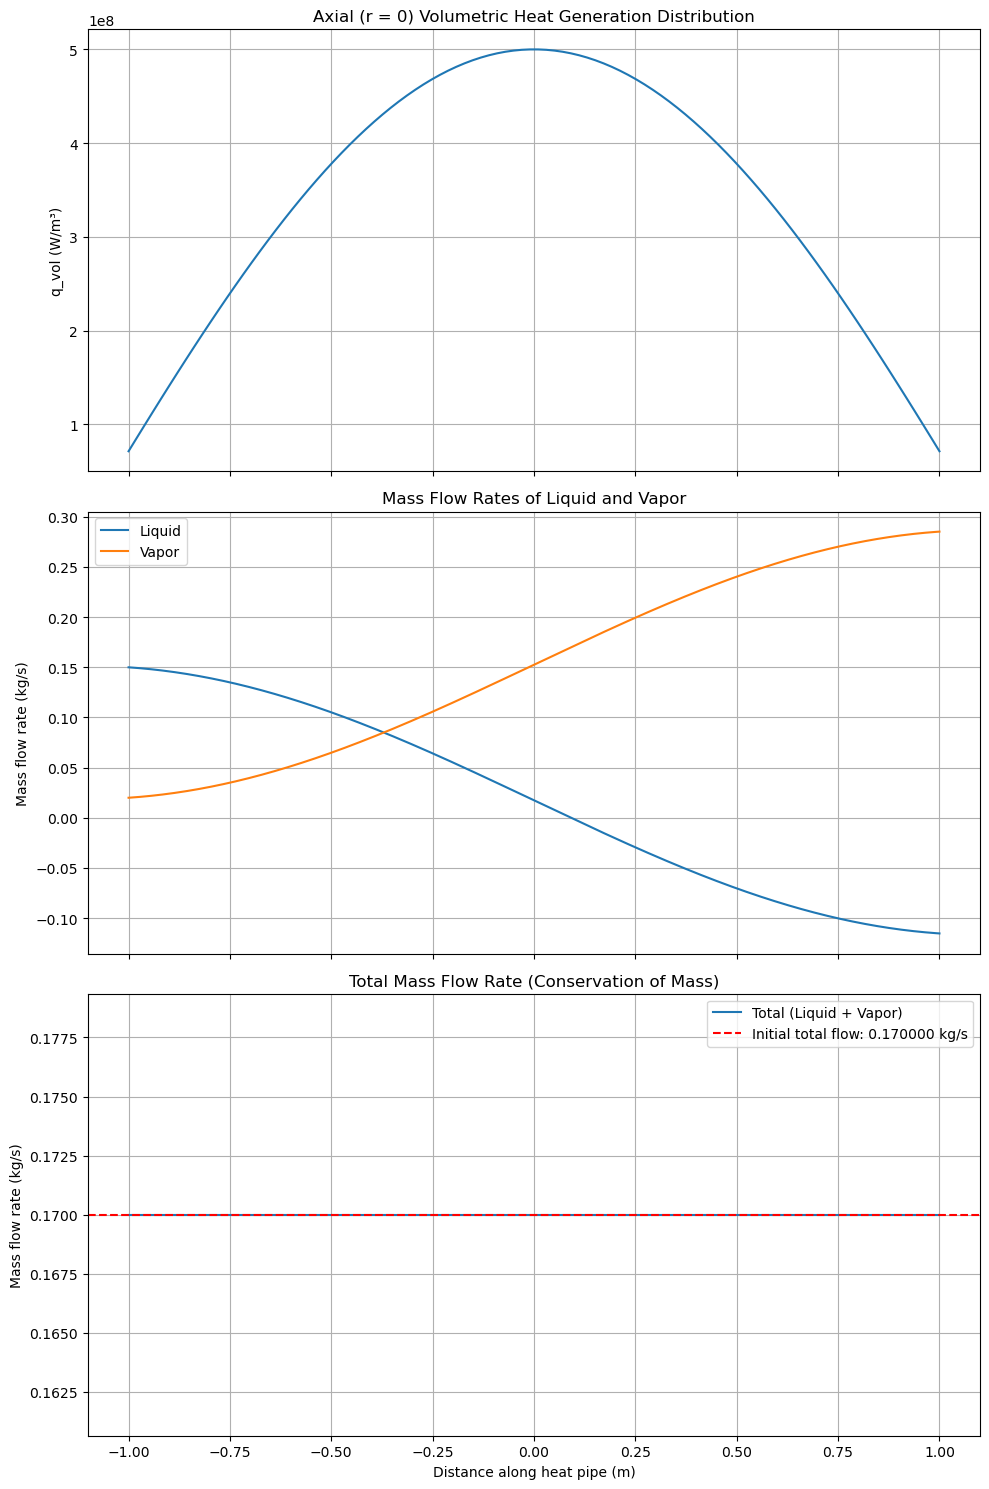

Initial total mass flow rate: 0.170000 kg/s
Final total mass flow rate: 0.170000 kg/s
Difference: 0.000000000 kg/s

Total evaporation along the heat pipe: 0.265219 kg/s
Final liquid mass flow rate: -0.115219 kg/s
Final vapor mass flow rate: 0.285219 kg/s
Average evaporation flux: 176.81 kg/(m^2·s)


In [11]:
import numpy as np
from scipy import integrate
import matplotlib.pyplot as plt
import pandas as pd
from scipy.interpolate import interp1d

def create_default_q_vol(H, d, num_points=100, q_max=500e6):
    """
    Create a default heat flux distribution using a cosine function with buffer zones.
    """
    z = np.linspace(-H/2, H/2, num_points)
    q = q_max * np.cos(np.pi * z / (H + 2*d))
    return pd.DataFrame({'z': z, 'q_vol': q})

def load_q_vol(filename=None, H=1.0, d=0.1, num_points=100):
    """
    Load q_vol data from a CSV file or create a default distribution.
    Returns an interpolation function.
    """
    if filename:
        try:
            data = pd.read_csv(filename)
        except FileNotFoundError:
            print(f"File {filename} not found. Using default distribution.")
            data = create_default_q_vol(H, d, num_points)
    else:
        data = create_default_q_vol(H, d, num_points)
    
    return interp1d(data['z'], data['q_vol'], kind='linear', fill_value='extrapolate'), data

def dm_dz(z, q_func, fuel_area, latent_heat):
    """
    Differential equation for mass flow rate.
    """
    return fuel_area * q_func(z) / latent_heat

def calculate_mass_flow(z_start, z_end, q_func, fuel_area, latent_heat, num_points=1000):
    """
    Calculate the mass flow rate from z_start to z_end using Simpson's rule.
    """
    z = np.linspace(z_start, z_end, num_points)
    integrand = dm_dz(z, q_func, fuel_area, latent_heat)
    return integrate.simpson(y=integrand, x=z)

# Parameters
filename = 'heat_flux_distribution.csv'  # Set to None to use default distribution
H = 2.0  # m, length of the heat pipe
d = 0.1  # m, buffer zone length
fuel_area = 15e-4  # m^2, converted from 15 cm^2
latent_heat = 3920000  # J/kg, latent heat of vaporization
initial_liquid_flow = 0.15  # kg/s
initial_vapor_flow = 0.02  # kg/s

# Load q_vol data or create default
q_func, data = load_q_vol(filename, H, d)

# Create array of z values
num_points = 1000  # Increased number of points for better resolution
z_values = np.linspace(-H/2, H/2, num_points)

# Calculate evaporation rate at each point
evaporation_rates = [dm_dz(z, q_func, fuel_area, latent_heat) for z in z_values]

# Calculate cumulative evaporation for each z value
cumulative_evaporation = [calculate_mass_flow(-H/2, z, q_func, fuel_area, latent_heat) for z in z_values]

# Calculate mass flow rates with initial values
liquid_mass_flow = [initial_liquid_flow - evap for evap in cumulative_evaporation]
vapor_mass_flow = [initial_vapor_flow + evap for evap in cumulative_evaporation]

# Calculate total mass flow (should be constant if mass is conserved)
total_mass_flow = [liquid + vapor for liquid, vapor in zip(liquid_mass_flow, vapor_mass_flow)]

# Plot the results
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 15), sharex=True)

# Plot heat flux distribution
ax1.plot(data['z'], data['q_vol'])
ax1.set_title(f'Axial (r = 0) Volumetric Heat Generation Distribution')
ax1.set_ylabel('q_vol (W/m³)')
ax1.grid(True)

# Plot combined liquid and vapor mass flow rates
ax2.plot(z_values, liquid_mass_flow, label='Liquid')
ax2.plot(z_values, vapor_mass_flow, label='Vapor')
ax2.set_title('Mass Flow Rates of Liquid and Vapor')
ax2.set_ylabel('Mass flow rate (kg/s)')
ax2.grid(True)
ax2.legend()

# Plot total mass flow rate to show conservation of mass
ax3.plot(z_values, total_mass_flow, label='Total (Liquid + Vapor)')
ax3.set_title('Total Mass Flow Rate (Conservation of Mass)')
ax3.set_xlabel('Distance along heat pipe (m)')
ax3.set_ylabel('Mass flow rate (kg/s)')
ax3.grid(True)
ax3.legend()

# Add a horizontal line at the initial total mass flow rate
initial_total_flow = initial_liquid_flow + initial_vapor_flow
ax3.axhline(y=initial_total_flow, color='r', linestyle='--', 
            label=f'Initial total flow: {initial_total_flow:.6f} kg/s')
ax3.legend()

plt.tight_layout()
plt.show()

# Calculate and print results
total_evaporation = cumulative_evaporation[-1]
final_liquid_flow = liquid_mass_flow[-1]
final_vapor_flow = vapor_mass_flow[-1]
final_total_flow = total_mass_flow[-1]
average_mass_flux = total_evaporation / fuel_area

print(f"Initial total mass flow rate: {initial_total_flow:.6f} kg/s")
print(f"Final total mass flow rate: {final_total_flow:.6f} kg/s")
print(f"Difference: {final_total_flow - initial_total_flow:.9f} kg/s")
print(f"\nTotal evaporation along the heat pipe: {total_evaporation:.6f} kg/s")
print(f"Final liquid mass flow rate: {final_liquid_flow:.6f} kg/s")
print(f"Final vapor mass flow rate: {final_vapor_flow:.6f} kg/s")
print(f"Average evaporation flux: {average_mass_flux:.2f} kg/(m^2·s)")

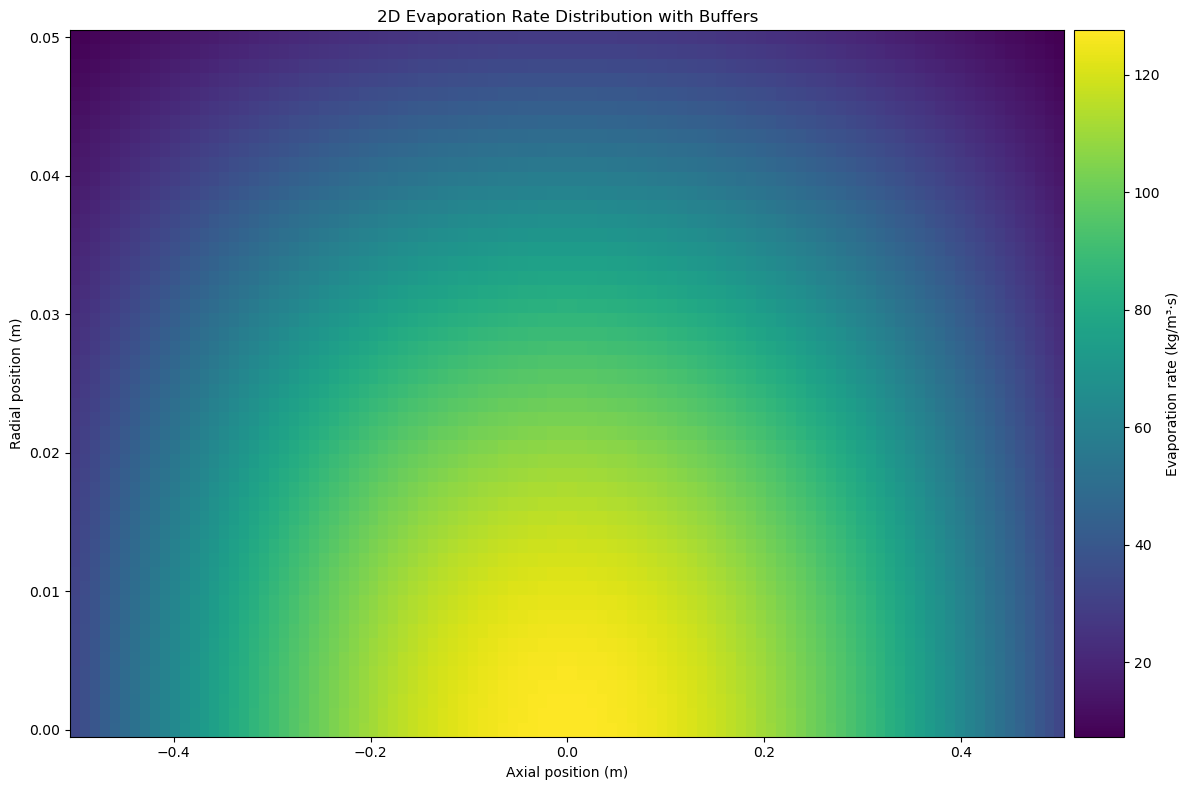

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

In [2]:
# Vessel parameters
d_vessel = 100      # Diameter of the vessel (cm)
h_vessel = 100      # Height of the vessel (cm)
gap_vessel = 1      # Gap between the vessel and internal components (cm)
thick_vessel = 0.3  # Thickness of the vessel wall (cm)

# Lattice parameters
h_lattice = (h_vessel/2)  # Height of the lattice (50 cm), half of vessel height
r_lattice = 0.5*(d_vessel-(2*gap_vessel)-(2*thick_vessel))  # Radius of the lattice (47 cm)

# Fuel pin parameters
r_pin_out = 0.7     # Outer radius of the fuel pin (cm), diameter = 1.4 cm
r_pin_mid = 0.5     # Middle radius of the fuel pin (cm), diameter = 1.0 cm
r_pin_in = 0.4      # Inner radius of the fuel pin (cm), diameter = 0.8 cm

# Lattice geometry
edge = 2.5          # Edge length of the hexagonal lattice cell (cm)
s = 2.165           # Distance between centers of adjacent fuel pins (cm)
corner = sqrt(edge*2 - s*2)  # Distance from center to corner of hexagonal cell

# Plenum parameters
d_plenum = 140      # Diameter of the plenum (cm)
h_natrium = 10      # Height of the sodium layer (cm)
h_plenum = 20       # Height of the plenum (cm)

pitch =3.5

In [4]:
meniscus_angle = 0
liquid_surface_tension = 0.058917
pore_radius = 20e-6
liquid_density = 958.37
vapor_density = 0.59766

z_max = 2*liquid_surface_tension*np.cos(meniscus_angle)/(pore_radius*(liquid_density-vapor_density)*g)
z_max

0.6272745370786194

In [7]:
# Given parameters
edge = 2.5          # cm (edge length of hexagonal cell)
r_pin_out = 0.7     # cm (outer radius of the fuel pin/heat pipe)

# Calculate area of hexagonal cell
area_hex = 3 * math.sqrt(3) * edge**2 / 2

# Calculate area of heat pipe/fuel pin
area_pin = math.pi * r_pin_out**2

# Calculate fuel lattice area (per cell)
area_fuel_lattice = area_hex - area_pin

# Print results
print(f"Area of hexagonal cell: {area_hex:.4f} cm²")
print(f"Area of heat pipe/fuel pin: {area_pin:.4f} cm²")
print(f"Fuel lattice area (per cell): {area_fuel_lattice:.4f} cm²")

# Calculate total fuel lattice area
r_lattice = 47  # cm (radius of the lattice)
h_lattice = 50  # cm (height of the lattice)

# Estimate number of cells in the lattice
cell_area = 3 * math.sqrt(3) * edge**2 / 2
lattice_cross_section = math.pi * r_lattice**2
estimated_cells = lattice_cross_section / cell_area

total_fuel_lattice_area = area_fuel_lattice * estimated_cells

print(f"\nEstimated number of cells in lattice: {estimated_cells:.0f}")
print(f"Total fuel lattice area: {total_fuel_lattice_area:.2f} cm²")
print(f"Total fuel lattice volume: {total_fuel_lattice_area * h_lattice:.2f} cm³")

Area of hexagonal cell: 16.2380 cm²
Area of heat pipe/fuel pin: 1.5394 cm²
Fuel lattice area (per cell): 14.6986 cm²

Estimated number of cells in lattice: 427
Total fuel lattice area: 6281.88 cm²
Total fuel lattice volume: 314093.93 cm³
